# Полиномиальная регрессия

**Полиномиальная регрессия** — это метод математической статистики и машинного обучения, который используется для моделирования нелинейной зависимости между независимой переменной и зависимой переменной.

Несмотря на название, полиномиальная регрессия является частным случаем линейной регрессии, так как остаётся линейной по параметрам модели.

Метод широко применяется в анализе данных, эконометрике, физике, инженерии и машинном обучении, когда линейная модель недостаточно точно описывает данные.

## Что такое полиномиальная регрессия

Полиномиальная регрессия **аппроксимирует** зависимость между переменными с помощью полинома степени $n$.

### Если у нас один признак

Вспомним уравнение простой линейной регрессии для одного признака $x$:

$$y = w_0 + w_1*x_1$$

- $w_0$ - свободный коэффицент
- $w_1$ - коэффицент при $x1$ (вес этого признака)
- $x_1$ - признак №1 (например, рост человека)

Полиномиальная регрессия берёт эту идею и расширяет ее.
Если у нас есть один исходный признак $x_1$, мы добавляем его степени: $x^2$ ($x$ в квадрате), $x^3$ ($x$ в кубе) и так далее, до некоторой степени $n$. Уравнение полиномиальной регрессии степени $n$ для одного признака выглядит так:

$$y = w_0 + w_1*x_1 + w_2*x_1^2 + w_3*x_1^3 + ... + w_n*x_1^n$$

**Если $n = 1$, модель превращается в обычную линейную регрессию.**

### Если у нас много признаков

А если у нас несколько признаков ($x_1, x_2, ..., x_d$), то помимо степеней каждого признака ($x_1^2, x_1^3, ..., x_2^2, ..., x_d^2, ..., x_d^n$, и т.д.), которые улавливают нелинейность по каждой оси, мы также добавляем их перекрестные произведения (взаимодействия), такие как `x₁*x₂`, `x₁²*x₂`, `x₁*x₂²` и т.д., вплоть до суммарной степени `n`. Например, для двух признаков (`x₁`, `x₂`) и степени `n=2`, уравнение будет включать:

$$y = w_0 + w₁x₁ + w₂x₂ + w₃x₁² + w₄x₂² + w₅(x₁*x₂)$$

Эти взаимодействия позволяют модели учесть ситуации, когда эффект одного признака (`x₁`) на целевую переменную (`y`) зависит от значения другого признака (`x₂`). Без члена взаимодействия модель предполагает, что эффект `x₁` всегда одинаков, независимо от `x₂`. Это делает модель значительно более гибкой в многомерном пространстве.

In [ ]:
# здесь три объёкта - три строки
# три признака у каждого объекта - три столбца в массиве
X = [[ 2,   4,   8],
    [ 3,   9,  27],
    [ 4,  16,  64]]

Пример: degree=2, входные признаки `x₁`, `x₂` (два столбца): `[[a, b], [c, d]]` (`a`, `c` - значения `x₁`; `b`, `d` - значения `x₂`).
Создав полиномы, мы получим пять столбцов: `x₁`, `x₂`, `x₁²`, `x₁*x₂`, `x₂²`:
```
[[a,  b,  a²,  a*b,  b²],
 [c,  d,  c²,  c*d,  d²]]
```

**Ключевая идея: нелинейную зависимость можно аппроксимировать линейной моделью, если добавить новые признаки.**

Если мы теперь мысленно переобозначим наши признаки: \
`z₁ = x₁`\
`z₂ = x₂`\
`z₃ = x₁²`\
`z₄ = x₂²`\
`z₅ = x₁*x₂`

То уравнение превращается в:

$$y = w₀ + w₁z₁ + w₂z₂ + w₃z₃ + w₄z₄ + w₅z₅$$

**Это не что иное, как уравнение обычной множественной линейной регрессии!**

Зависимость `y` от исходных `x` стала нелинейной. Но зависимость `y` от набора новых признаков (`z₁`, `z₂`, `z₃`, ...) остается линейной. Модель линейна относительно коэффициентов `w`.

Именно поэтому для обучения полиномиальной регрессии (т.е. нахождения оптимальных `w`) мы используем те же методы, что и для обычной линейной регрессии, чаще всего — метод наименьших квадратов (OLS).

Алгоритм просто работает с расширенной матрицей признаков, которую мы получили после полиномиальной трансформации.

## Что это значит ?

1. Больше гибкости. Каждый добавленный член (`w₂x²`, `w₃x³`, ...) дает нашей модели дополнительную "степень свободы". Если линейная регрессия может провести только прямую, то полиномиальная регрессия степени 2 (квадратичная) может описать параболу, степени 3 (кубическая) — более сложную S-образную кривую, и так далее. Чем выше степень `n`, тем более сложную форму может принять наша регрессионная кривая.
2. Трансформация признаков. Ключевой момент заключается в том, что мы не меняем сам метод регрессии. Мы преобразуем наши входные данные. Вместо одного признака `x` мы создаем набор признаков: `x`, `x²`, `x³`, ..., `xⁿ`. А затем мы обучаем обычную линейную регрессию на этом новом, расширенном наборе признаков. Модель ищет оптимальные коэффициенты `w₀`, `w₁`, `w₂`, ..., `wₙ` для этой "линейной" комбинации исходного признака и его степеней.
3. Визуальное отличие. На графике это самое заметное различие. Вместо прямой линии, которая может плохо проходить через облако точек, полиномиальная регрессия строит кривую, которая может гораздо лучше описывать данные.


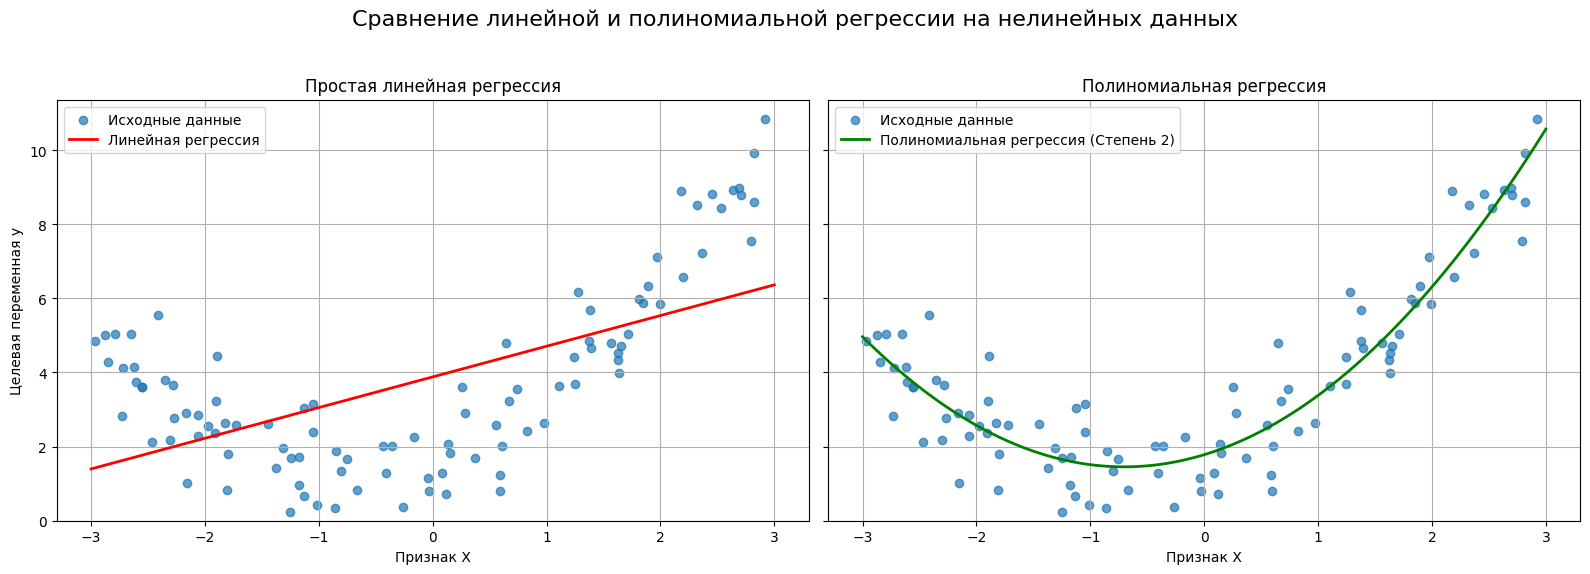

Итог: полиномиальная регрессия — это способ заставить линейную модель работать с нелинейными зависимостями путем добавления новых признаков, основанных на степенях исходных.

## Практический пример

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.pipeline import make_pipeline

In [ ]:
data = sns.load_dataset('mpg')

data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 398 entries, 0 to 397
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   mpg           398 non-null    float64
 1   cylinders     398 non-null    int64  
 2   displacement  398 non-null    float64
 3   horsepower    392 non-null    float64
 4   weight        398 non-null    int64  
 5   acceleration  398 non-null    float64
 6   model_year    398 non-null    int64  
 7   origin        398 non-null    object 
 8   name          398 non-null    object 
dtypes: float64(4), int64(3), object(2)
memory usage: 28.1+ KB


In [ ]:
data

,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,name
0,18.0,8,307.0,130.0,3504,12.0,70,usa,chevrolet chevelle malibu
1,15.0,8,350.0,165.0,3693,11.5,70,usa,buick skylark 320
2,18.0,8,318.0,150.0,3436,11.0,70,usa,plymouth satellite
3,16.0,8,304.0,150.0,3433,12.0,70,usa,amc rebel sst
4,17.0,8,302.0,140.0,3449,10.5,70,usa,ford torino
...,...,...,...,...,...,...,...,...,...
393,27.0,4,140.0,86.0,2790,15.6,82,usa,ford mustang gl
394,44.0,4,97.0,52.0,2130,24.6,82,europe,vw pickup
395,32.0,4,135.0,84.0,2295,11.6,82,usa,dodge rampage
396,28.0,4,120.0,79.0,2625,18.6,82,usa,ford ranger


In [ ]:
print(f"\nКоличество пропусков в 'horsepower' до обработки: {data['horsepower'].isnull().sum()}")

data = data.dropna(subset=['horsepower'])

print(f"Количество пропусков в 'horsepower' после удаления: {data['horsepower'].isnull().sum()}")


Количество пропусков в 'horsepower' до обработки: 6
Количество пропусков в 'horsepower' после удаления: 0


In [ ]:
X = data[['horsepower']]
y = data['mpg']

# Разделяем данные на обучающую и тестовую выборки
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"\nРазмер обучающей выборки: {X_train.shape[0]} записей")
print(f"Размер тестовой выборки: {X_test.shape[0]} записей")


Размер обучающей выборки: 313 записей
Размер тестовой выборки: 79 записей


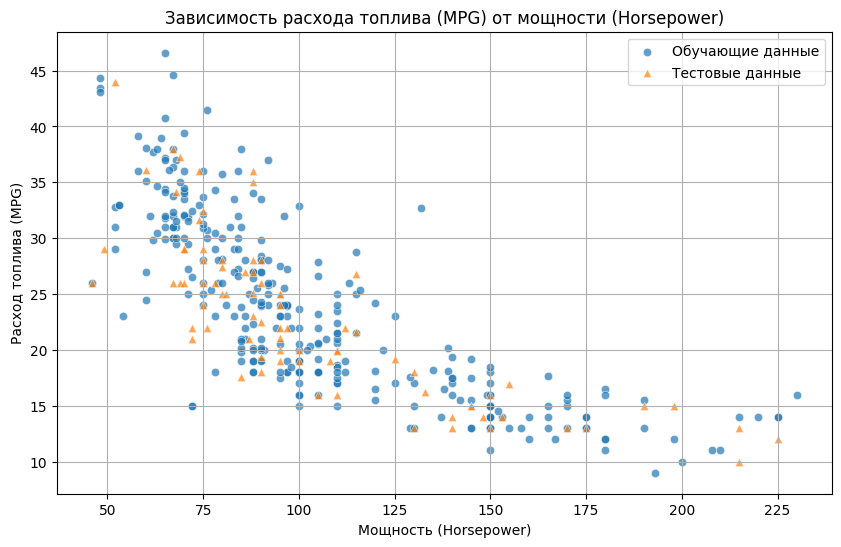

In [ ]:
plt.figure(figsize=(10, 6))
sns.scatterplot(x=X_train['horsepower'], y=y_train, alpha=0.7, label='Обучающие данные')
sns.scatterplot(x=X_test['horsepower'], y=y_test, alpha=0.7, label='Тестовые данные', marker='^')
plt.title('Зависимость расхода топлива (MPG) от мощности (Horsepower)')
plt.xlabel('Мощность (Horsepower)')
plt.ylabel('Расход топлива (MPG)')
plt.legend()
plt.grid(True)
plt.show()

## Построим простую линейную регрессию (без полинома)

In [ ]:
# Обучаем простую линейную регрессию
lin_reg = LinearRegression()
lin_reg.fit(X_train, y_train)

# Делаем предсказания на тестовой выборке
y_lin_pred_test = lin_reg.predict(X_test)

lin_r2 = r2_score(y_test, y_lin_pred_test)
print(f"Линейная регрессия (на тесте): R^2 = {lin_r2:.3f}")

Линейная регрессия (на тесте): R^2 = 0.566


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


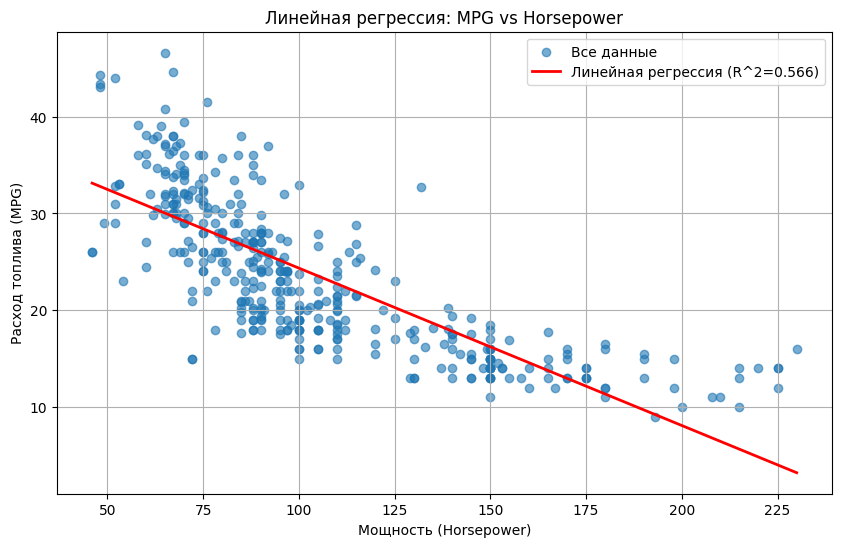

In [ ]:
plt.figure(figsize=(10, 6))
plt.scatter(X['horsepower'], y, alpha=0.6, label='Все данные')

X_plot = np.linspace(X['horsepower'].min(), X['horsepower'].max(), 100).reshape(-1, 1)
y_lin_plot = lin_reg.predict(X_plot)

plt.plot(X_plot, y_lin_plot, color='red', linewidth=2, label=f'Линейная регрессия (R^2={lin_r2:.3f})')
plt.title('Линейная регрессия: MPG vs Horsepower')
plt.xlabel('Мощность (Horsepower)')
plt.ylabel('Расход топлива (MPG)')
plt.legend()
plt.grid(True)
plt.show()

## Построим полиномиальную регрессию (второй степени)

Возьмем метод из библиотеки `sklearn` - `PolynomialFeatures`, который создаёт полимиальные признаки.

`PolynomialFeatures` не обучает модель, а только преобразует входные признаки.

Он берёт исходные признаки и добавляет:

- степени признаков
- их произведения (если признаков несколько)
- при необходимости — константный признак

**Документация:**

https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.PolynomialFeatures.html

In [ ]:
from sklearn.preprocessing import PolynomialFeatures

# Степень полинома
degree = 2

# 1. Создаём объект для полиномиальных признаков
poly = PolynomialFeatures(degree=degree, include_bias=False)

# 2. Преобразуем обучающие данные
X_train_poly = poly.fit_transform(X_train)

In [ ]:
X_train_poly[:4]

# 110 - это исходное значение признака horsepower для 1 строки
# 12100 (110**2) - это 2 степень признака horsepower для 1 строки

array([[  110., 12100.],
       [   92.,  8464.],
       [   97.,  9409.],
       [  150., 22500.]])

In [ ]:
# 3. Обучаем линейную регрессию на полиномиальных признаках
model = LinearRegression()
model.fit(X_train_poly, y_train)

LinearRegression()

In [ ]:
# 4. Преобразуем тестовые данные
X_test_poly = poly.transform(X_test)

# 5. Делаем предсказания
y_poly_pred_test = model.predict(X_test_poly)

# 6. Оцениваем качество модели
poly_r2 = r2_score(y_test, y_poly_pred_test)

print(f"\nПолиномиальная регрессия (degree={degree}, на тесте): R^2 = {poly_r2:.3f}")


Полиномиальная регрессия (degree=2, на тесте): R^2 = 0.639


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but PolynomialFeatures was fitted with feature names
  warnings.warn(


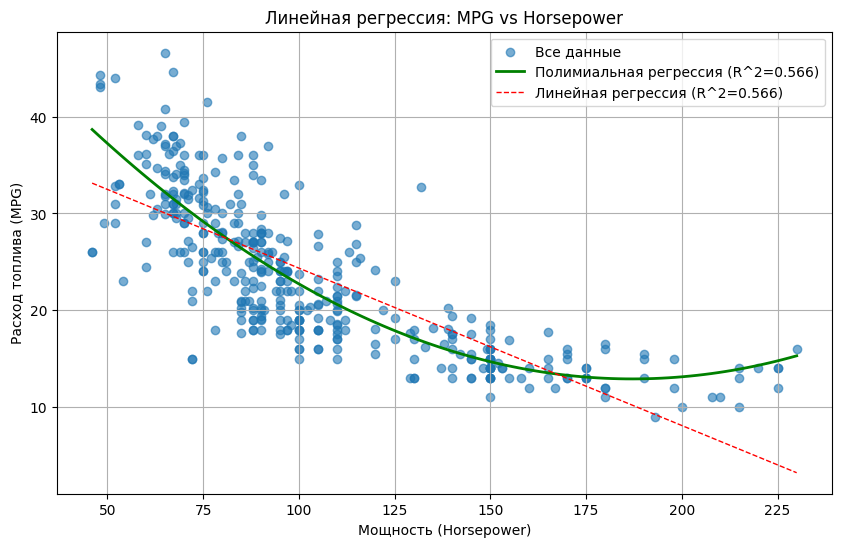

In [ ]:
plt.figure(figsize=(10, 6))
plt.scatter(X['horsepower'], y, alpha=0.6, label='Все данные')

X_plot = np.linspace(X['horsepower'].min(), X['horsepower'].max(), 100).reshape(-1, 1)

X_plot_poly = poly.transform(X_plot)
y_poly_plot = model.predict(X_plot_poly)

plt.plot(X_plot, y_poly_plot, color='green', linewidth=2, label=f'Полимиальная регрессия (R^2={lin_r2:.3f})')
plt.plot(X_plot, y_lin_plot, color='red', linewidth=1, linestyle='--', label=f'Линейная регрессия (R^2={lin_r2:.3f})')

plt.title('Линейная регрессия: MPG vs Horsepower')
plt.xlabel('Мощность (Horsepower)')
plt.ylabel('Расход топлива (MPG)')
plt.legend()
plt.grid(True)
plt.show()

# Переобучение и выбор степени полинома

**Переобучение (overfitting)** в ML — это когда модель слишком точно «зазубривает» тренировочные данные вместе с шумом и случайностями, вместо того чтобы учить общие закономерности. В итоге она показывает идеальную точность на старых данных, но дает плохие результаты на новых, теряя способность к обобщению.

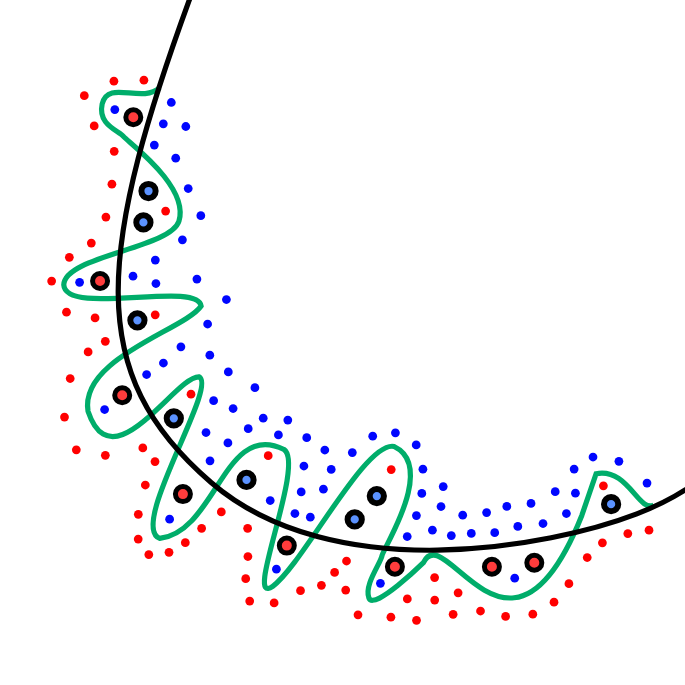


Зеленая линия - переобученная модель.

Черная - вполне хорошо обученная модель.

_______________________

В связи с этим выбор степени полинома является сложной задачей.

Слишком простая модель (низкая степень полинома) не уловит тренд, а слишком сложная (высокая степень) начнет подстраиваться под случайный шум в обучающих данных.

Давайте посмотрим, как выглядят модели с разными степенями полинома на наших данных MPG vs Horsepower. Мы также рассчитаем качество моделей (R²) на обучающей и тестовой выборках для каждой степени.

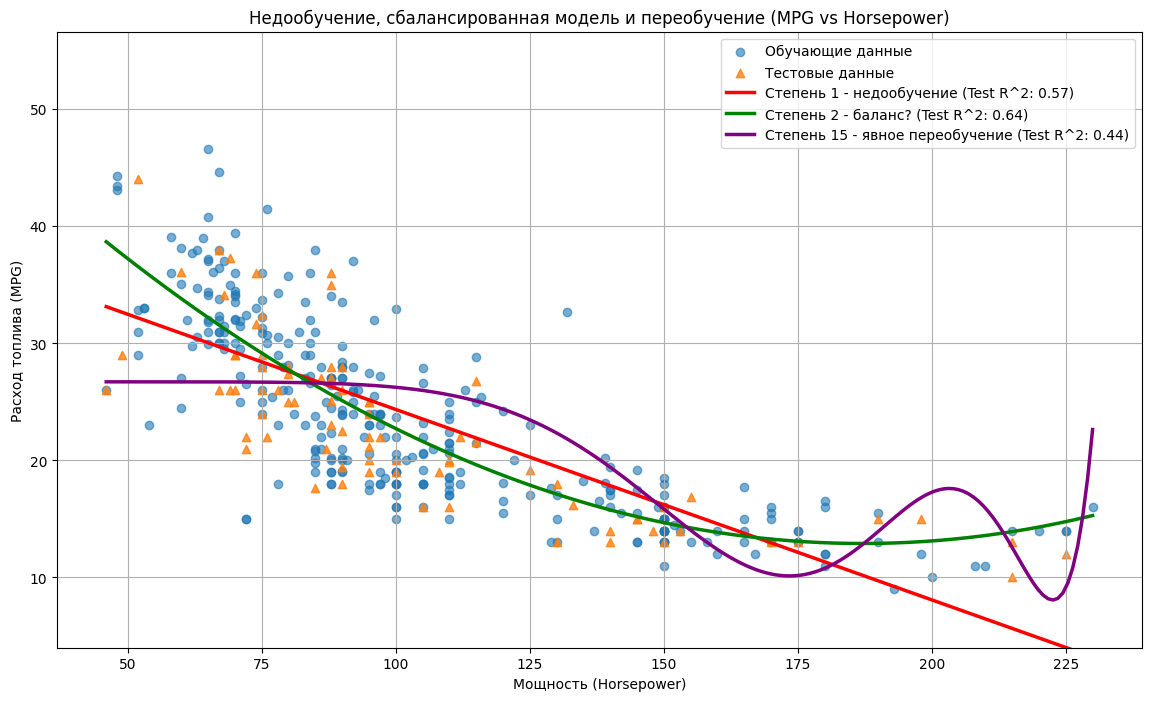


Сравнение R^2 для разных степеней:
Степень 1: Train R^2 = 0.61, Test R^2 = 0.57
Степень 2: Train R^2 = 0.70, Test R^2 = 0.64
Степень 15: Train R^2 = 0.42, Test R^2 = 0.44


In [ ]:
X_plot = np.linspace(X['horsepower'].min(), X['horsepower'].max(), 200).reshape(-1, 1)
X_plot_df = pd.DataFrame(X_plot, columns=['horsepower'])

degrees = [1, 2, 15] # Степени для сравнения: недообучение, баланс, переобучение
colors = ['red', 'green', 'purple']
labels = ["Степень 1 - недообучение",
          "Степень 2 - баланс?",
          "Степень 15 - явное переобучение"]

train_r2s = []
test_r2s = []

plt.figure(figsize=(14, 8))
plt.scatter(X_train['horsepower'], y_train, alpha=0.6, label='Обучающие данные')
plt.scatter(X_test['horsepower'], y_test, alpha=0.8, marker='^', label='Тестовые данные')

for i, degree in enumerate(degrees):
    model = make_pipeline(
        PolynomialFeatures(degree, include_bias=False),
        LinearRegression()
    )
    model.fit(X_train, y_train)

    # Предсказания для графика
    y_plot_pred = model.predict(X_plot_df)

    # Предсказания для оценки R^2
    y_train_pred = model.predict(X_train)
    y_test_pred = model.predict(X_test)

    # Расчет R^2
    train_r2 = r2_score(y_train, y_train_pred)
    test_r2 = r2_score(y_test, y_test_pred)
    train_r2s.append(train_r2)
    test_r2s.append(test_r2)

    # Рисуем кривую
    plt.plot(X_plot, y_plot_pred, color=colors[i], linewidth=2.5,
             label=f"{labels[i]} (Test R^2: {test_r2:.2f})")

plt.title('Недообучение, сбалансированная модель и переобучение (MPG vs Horsepower)')
plt.xlabel('Мощность (Horsepower)')
plt.ylabel('Расход топлива (MPG)')
plt.legend(loc='upper right')
plt.grid(True)
# Ограничим ось Y для наглядности, иначе кривая степени 15 может улететь
plt.ylim(data['mpg'].min() - 5, data['mpg'].max() + 10)
plt.show()

# Выведем R^2 для сравнения
print("\nСравнение R^2 для разных степеней:")
for i, degree in enumerate(degrees):
    print(f"Степень {degree}: Train R^2 = {train_r2s[i]:.2f}, Test R^2 = {test_r2s[i]:.2f}")

# Сравнение R^2 для разных степеней:
# Степень 1: Train R^2 = 0.61, Test R^2 = 0.57
# Степень 2: Train R^2 = 0.70, Test R^2 = 0.64
# Степень 15: Train R^2 = 0.42, Test R^2 = 0.44

# Как выбрать оптимальную степень полинома?

Можно построить графики для нескольких степеней и выбрать ту, которая хорошо описывает зависимость, но не выглядит слишком "извилистой" или неправдоподобной. Можно ещё построить график зависимости ошибки на обучающей и тестовой выборках от степени полинома. Ошибка на обучении будет падать с ростом степени, а ошибка на тесте сначала упадет, а потом начнет расти (точка начала роста — признак переобучения). Ищем "локоть" или минимум на кривой тестовой ошибки.

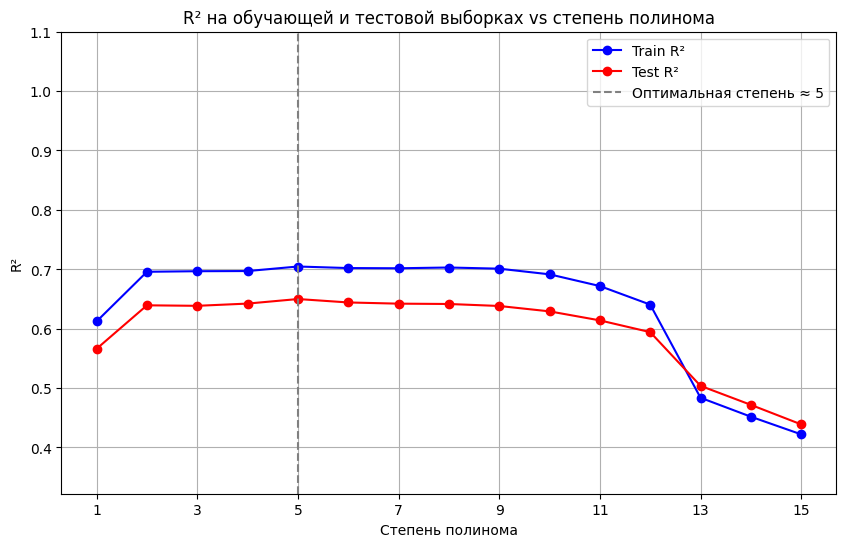


Максимальный R² на тесте (R²=0.65) достигается при степени 5


In [ ]:
# --- Построение графика R² от степени полинома ---
degrees_to_test = range(1, 16) # Протестируем степени от 1 до 15
train_scores = []
test_scores = []

for degree in degrees_to_test:
    model = make_pipeline(
        PolynomialFeatures(degree, include_bias=False),
        LinearRegression()
    )
    model.fit(X_train, y_train)

    y_train_pred = model.predict(X_train)
    y_test_pred = model.predict(X_test)

    train_scores.append(r2_score(y_train, y_train_pred))
    test_scores.append(r2_score(y_test, y_test_pred))

plt.figure(figsize=(10, 6))
plt.plot(degrees_to_test, train_scores, 'bo-', label='Train R²')
plt.plot(degrees_to_test, test_scores, 'ro-', label='Test R²')
plt.xlabel('Степень полинома')
plt.ylabel('R²')
plt.title('R² на обучающей и тестовой выборках vs степень полинома')
plt.legend()
plt.grid(True)

# Отметим максимум на тестовой кривой
best_degree_idx = np.argmax(test_scores)
best_degree = degrees_to_test[best_degree_idx]
plt.axvline(best_degree, linestyle='--', color='gray', label=f'Оптимальная степень ≈ {best_degree}')
plt.legend()
plt.ylim(min(train_scores + test_scores) - 0.1, 1.1) # Настроить масштаб оси Y
plt.xticks(degrees_to_test[::2]) # Показать не все тики на оси X
plt.show()

print(f"\nМаксимальный R² на тесте (R²={test_scores[best_degree_idx]:.2f}) достигается при степени {best_degree}")
# Максимальный R² на тесте (R²=0.65) достигается при степени 5

R² на тесте растет вначале, но затем достигает максимума (в нашем случае, при степени 5) и после этого начинает немного снижаться. Точка максимума указывает на оптимальную сложность модели. Снижение после максимума — явный признак того, что модель становится слишком сложной и начинает переобучаться, теряя качество на новых данных.

**Что ещё можно улучшить?**

- Использовать **кросс-валидацию**. Данные многократно разбиваются на обучающие и валидационные фолды, модель обучается и оценивается несколько раз для каждой степени. Результаты усредняются. Scikit-learn имеет встроенные инструменты для кросс-валидации (например, cross_val_score или GridSearchCV для поиска оптимальной степени).
- **Принцип простоты/экономности (бритва Оккама)**. Если две модели с разными степенями дают примерно одинаковое качество на валидационных/тестовых данных, выбираем более простую модель.
- **Регуляризация**. Вместо того чтобы подбирать степень, можно использовать полином достаточно высокой степени, но добавить к функции потерь штраф за большие коэффициенты модели (L1 - Lasso, L2 - Ridge). Это "сглаживает" кривую и борется с переобучением, не требуя явного выбора оптимальной степени (хотя требует подбора параметра регуляризации). Это особенно полезно, когда признаков много и есть взаимодействия.

# Регуляризация

**Регуляризация** — это способ ограничить сложность модели, добавляя штраф за большие значения параметров.

**Идея простая:**

```Если модель слишком гибкая → она подстраивается под шум → переобучается.```

Чтобы этого избежать, мы добавляем к функции ошибки дополнительный штраф.

**Обычная линейная регрессия**

$\hat y = w_0 + \sum_{i=1}^d w_i * x_i$

Функция потерь (MSE)^

$L(w) = MSE = \frac{1}{n} * \sum_{i=1}^n (y_i - \hat y_i)^2$

Где:
- $d$ - количество признаков
- $n$ - количество объектов

**Общая идея регуляризации**

Добавляем штраф:

$MSE + lambda * Omega(w)$

где $lambda >= 0$ — коэффициент регуляризации
$Omega(w)$ — штраф за сложность.

В ML есть два основных вида регуляризации. Википедия их описывает так:

1. **L1-регуляризация** (англ. lasso regression), или регуляризация через манхэттенское расстояние:

$$J_{lasso} = \sum_i (y_i - \hat y_i) + \lambda * \sum_i ||w_i||$$

Если короче, то прибавление к лосс-функции суммы весов в модуле. Она добавляет «критическую величину» коэффициента, как дополнение к функции потерь. То есть, если весы на расстоянии лямбда ближе к нулю, то они становятся равными нулю и уходят в игнор, тем самым отбирая только важные признаки и в следствии уменьшая саму сеть, что экономит ресурсы.

2. **L2- регуляризация**, или регуляризация Тихонова (в англоязычной литературе — ridge regression или Tikhonov regularization), для интегральных уравнений позволяет балансировать между соответствием данным и маленькой нормой решения:

$$J_{lasso} = \sum_i (y_i - \hat y_i) + \lambda * \sum_i w_i^2$$

Тут получается что функция занижает пики прибавляя сумму весов в квадрате с множителем лямбда.

В графике происходит легкое смещение (не дисперсия) добавляя статистическую ошибку, которая не влияет на точность, но позволяет не переобучиться. Соответственно если вы поставите большую коэффициент (лямбда) L2, то система никогда не обучится, просто из-за того что сильно сместиться. Но если лямбда будет маленькой то и смещение будет маленьким, и весь смысл регуляризации так же будет минимальным.

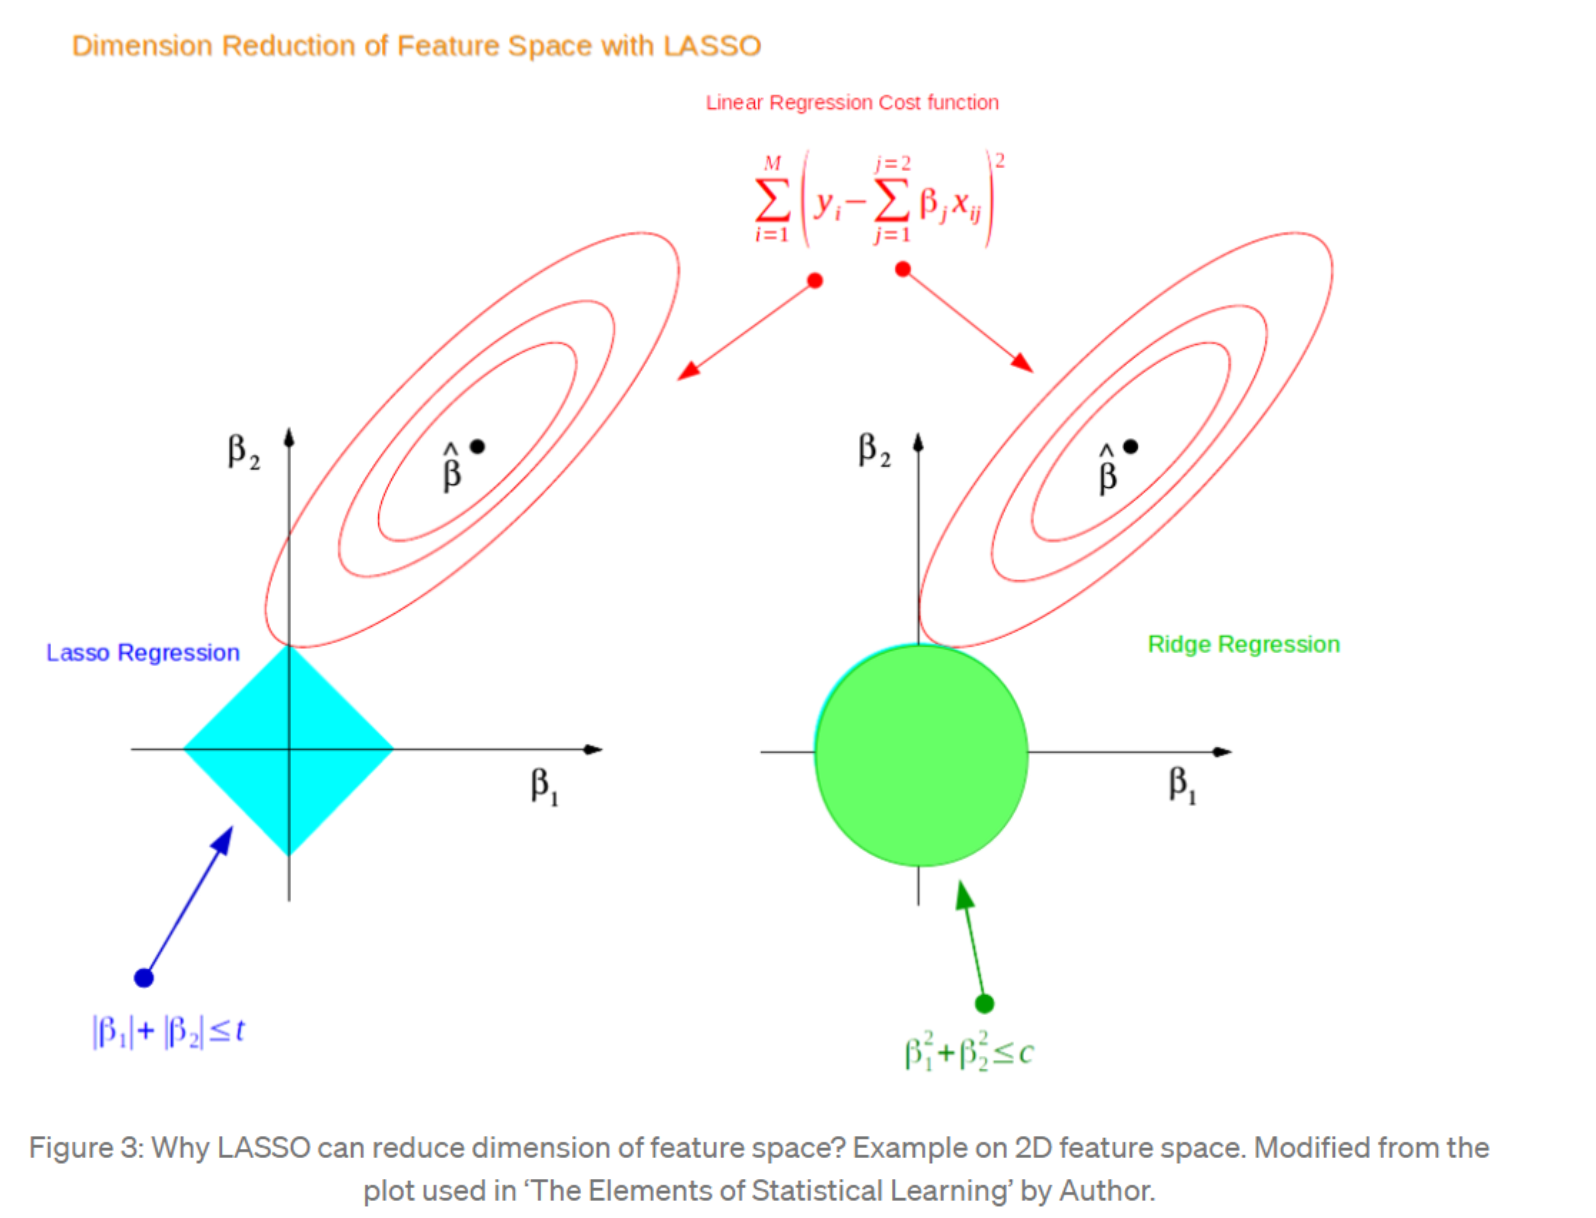

Регуляризация создает некое абстрактное поле (зеленое) в градиентном спуске (слоистые овалы) из которого не может выйти обучение сети. Когда на самом деле абсолютное дно обучения (B с шапочкой) находится за пределами этого поля. При этом логически если мы увеличиваем Лямбду, то поле сужается, то есть с увеличением шкалы нормализации весов, найти какое либо дно станет труднее (возникнет “пересглаженность” :) ).

In [ ]:
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error

data = data.dropna()

X = data[['horsepower']]
y = data['mpg']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Масштабирование (ВАЖНО для регуляризации!)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [ ]:
lr = LinearRegression()
lr.fit(X_train_scaled, y_train)

print("MSE test:", mean_squared_error(y_test, lr.predict(X_test_scaled)))

MSE test: 22.153237123863413


In [ ]:
ridge = Ridge(alpha=1.0)
ridge.fit(X_train_scaled, y_train)

print("MSE test:", mean_squared_error(y_test, ridge.predict(X_test_scaled)))

MSE test: 22.117448030472186


In [ ]:
from sklearn.linear_model import Lasso

lasso = Lasso(alpha=0.1)
lasso.fit(X_train_scaled, y_train)

print("MSE test:", mean_squared_error(y_test, lasso.predict(X_test_scaled)))

MSE test: 21.98089601533718


In [ ]:
from sklearn.linear_model import ElasticNet

elastic = ElasticNet(alpha=0.1, l1_ratio=0.5)
elastic.fit(X_train_scaled, y_train)

print("MSE test:", mean_squared_error(y_test, elastic.predict(X_test_scaled)))

MSE test: 21.64960231713851
